In [1]:
import numpy as np
import fastplotlib as fpl
from matplotlib import pyplot as plt

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


Incompatible version of wgpu:
    Detected 0.15.3.post97+g8a0b267, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [6]:
def get_x_t(c, t):
    return (c * np.array([-1, 1]) * np.exp(-t)).reshape(1, -1)

In [78]:
c = 1
n_t = 100
ts = np.zeros(n_t)

x_t = np.zeros((n_t, 2))
x_t_d_mag = np.zeros(n_t)

for i, t in enumerate(np.linspace(0, 5, 100)):
    ts[i] = t
    x_t[i] = get_x_t(c, t)
    if i > 0:
        x_t_d_mag[i] = np.linalg.norm(x_t[i] - x_t[i - 1], ord=2)

x_t_d_mag[0] = x_t_d_mag[1]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
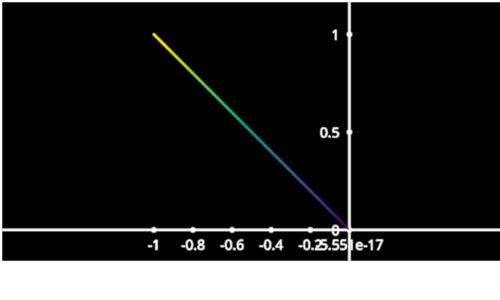

In [79]:
fig = fpl.Figure()

fig[0, 0].add_line(x_t, cmap="viridis", cmap_transform=x_t_d_mag)
fig[0, 0].axes.intersection = (0, 0, 0)

fig.show()

In [83]:
x_t_c = list()
x_t_d_mag_c = list()

for c in range(-5, 5):
    n_t = 100
    ts = np.zeros(n_t)
    
    x_t = np.zeros((n_t, 3))
    x_t[..., -1] = c
    x_t_d_mag = np.zeros(n_t)
    
    for i, t in enumerate(np.linspace(0, 5, 100)):
        ts[i] = t
        x_t[i, :-1] = get_x_t(c, t)
        if i > 0:
            x_t_d_mag[i] = np.linalg.norm(x_t[i, :-1] - x_t[i - 1, :-1], ord=2)
    
    x_t_d_mag[0] = x_t_d_mag[1]

    x_t_c.append(x_t)
    x_t_d_mag_c.append(x_t_d_mag)

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:266: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:266: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:278: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
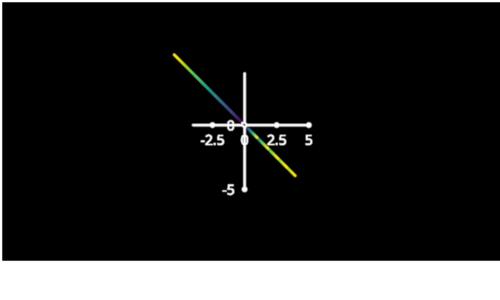

In [94]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

lines = fig[0, 0].add_line_collection(x_t_c, cmap="viridis", cmap_transform=x_t_d_mag_c)
for (line, co) in zip(lines, x_t_d_mag_c):
    line.cmap = "viridis"
    line.cmap.transform = co
fig[0, 0].axes.intersection = (0, 0, 0)
fig[0, 0].axes.z.visible = True
fig.show()

In [2]:
def get_x_t_2var(t, c1, c2):
    return ((c1 * np.array([-1, 1]) * np.exp(-t)) + (c2 * np.array([2, 3]) * np.exp(4 * t))).reshape(1, -1)

In [75]:
c1 = 1
c2 = 0.5

n_t = 100
ts = np.zeros(n_t)

x_t = np.zeros((n_t, 2))
x_t_d_mag = np.zeros(n_t)

t0 = -2
tend = 0.5

for i, t in enumerate(np.linspace(t0, tend, 100)):
    ts[i] = t
    x_t[i] = get_x_t_2var(t, c1, c2)
    if i > 0:
        x_t_d_mag[i] = np.linalg.norm(x_t[i] - x_t[i - 1], ord=2)

x_t_d_mag[0] = x_t_d_mag[1]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
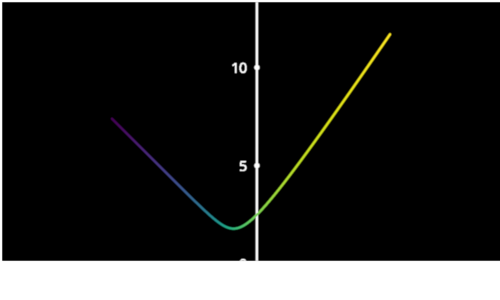

In [76]:
fig = fpl.Figure()

fig[0, 0].add_line(x_t, cmap="viridis")#, cmap_transform=x_t_d_mag)
fig[0, 0].axes.intersection = (0, 0, 0)

fig.show()

In [119]:
x_t_c = list()
x_t_d_mag_c = list()

for c1 in np.linspace(-1, 1, 8):
    for c2 in np.linspace(-0.2, 0.5, 8):
        n_t = 100
        ts = np.zeros(n_t)
        
        x_t = np.zeros((n_t, 2))
        x_t_d_mag = np.zeros(n_t)
        
        t0 = -1
        tend = 0.5
        
        for i, t in enumerate(np.linspace(t0, tend, 100)):
            ts[i] = t
            x_t[i] = get_x_t_2var(t, c1, c2)
            if i > 0:
                x_t_d_mag[i] = np.linalg.norm(x_t[i] - x_t[i - 1], ord=2)
    
        x_t_c.append(x_t)
        x_t_d_mag_c.append(x_t_d_mag)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
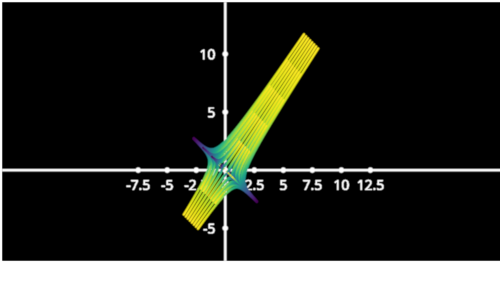

In [120]:
fig = fpl.Figure()#cameras="3d", controller_types="orbit")

lines = fig[0, 0].add_line_collection(x_t_c, cmap="viridis", cmap_transform=x_t_d_mag_c)
for (line, co) in zip(lines, x_t_d_mag_c):
    line.cmap = "viridis"
    # line.cmap.transform = co
fig[0, 0].axes.intersection = (0, 0, 0)
fig[0, 0].axes.z.visible = True
fig.show()

In [261]:
def get_x_t_2var_ep(t, c1, c2, matrix, ep):
    matrix = matrix * np.array([[1, 1], [1 / ep, 1 / ep]])
    
    (lam1, lam2), evecs = scipy.linalg.eig(matrix)
    eta1 = evecs[:, 0]
    eta2 = evecs[:, 1]
    
    return ((c1 * eta1 * np.exp(lam1 * t)) + (c2 * eta2 * np.exp(lam2 * t))).reshape(1, -1)

In [262]:
from ipywidgets import FloatSlider, VBox

In [281]:
# constants
START, STOP = -2, 2

T0, TEND = -1.5, 2

In [282]:
A = np.array([
    [1, 2],
    [3, 2]
])

A = np.array([
    [0, 1],
    [-2, -3]
])

x_t_c = list()
x_t_d_mag_c = list()

for c1 in np.linspace(START, STOP, 8):
    for c2 in np.linspace(START, STOP, 8):
        n_t = 100
        ts = np.zeros(n_t)
        
        x_t = np.zeros((n_t, 2))
        x_t_d_mag = np.zeros(n_t)
        
        t0 = T0
        tend = TEND
        
        for i, t in enumerate(np.linspace(t0, tend, 100)):
            ts[i] = t
            x_t[i] = get_x_t_2var_ep(t, c1, c2, A, ep=1.0)
            if i > 0:
                x_t_d_mag[i] = np.linalg.norm(x_t[i] - x_t[i - 1], ord=2)
    
        x_t_c.append(x_t)
        x_t_d_mag_c.append(x_t_d_mag)

/tmp/ipykernel_1904451/3755436905.py:27: ComplexWarning: Casting complex values to real discards the imaginary part
  x_t[i] = get_x_t_2var_ep(t, c1, c2, A, ep=1.0)


In [283]:
fig = fpl.Figure()#cameras="3d", controller_types="orbit")

lines = fig[0, 0].add_line_collection(x_t_c, cmap="viridis", cmap_transform=x_t_d_mag_c)
for (line, co) in zip(lines, x_t_d_mag_c):
    line.cmap = "viridis"
    # line.cmap.transform = co
fig[0, 0].axes.intersection = (0, 0, 0)
fig[0, 0].axes.z.visible = True

RFBOutputContext()

In [284]:
def update_epsilon(change):
    new_ep = change["new"]
    if new_ep == 0:
        return
        
    A = np.array([
        [1, 2],
        [3, 2]
    ])

    A = np.array([
        [0, 1],
        [-2, -3]
    ])
    
    x_t_c = list()
    x_t_d_mag_c = list()
    
    for c1 in np.linspace(START, STOP, 8):
        for c2 in np.linspace(START, STOP, 8):
            n_t = 100
            ts = np.zeros(n_t)
            
            x_t = np.zeros((n_t, 2))
            x_t_d_mag = np.zeros(n_t)
            
            t0 = T0
            tend = TEND
            
            for i, t in enumerate(np.linspace(t0, tend, 100)):
                ts[i] = t
                x_t[i] = get_x_t_2var_ep(t, c1, c2, A, ep=new_ep)
                if i > 0:
                    x_t_d_mag[i] = np.linalg.norm(x_t[i] - x_t[i - 1], ord=2)
        
            x_t_c.append(x_t)
            x_t_d_mag_c.append(x_t_d_mag)
            
    for line, x_t in zip(lines, x_t_c):
        line.data[:, :-1] = x_t

In [285]:
slider = FloatSlider(min=-1, max=1, step=0.025, value=1.0, description="epsilon")
slider.observe(update_epsilon, "value")

In [286]:
VBox([fig.show(), slider])

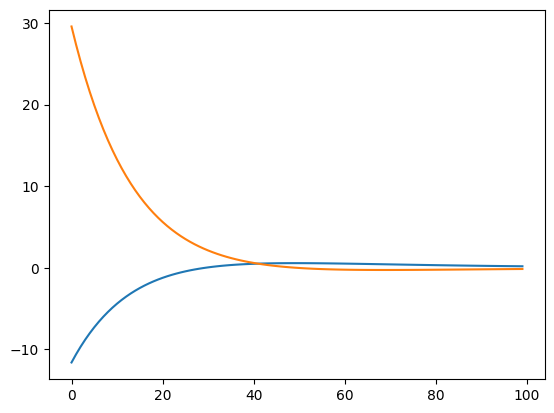

In [288]:
plt.plot(x_t)